# Micro-TDE rate density from loss-cone theory

Self-contained pipeline for the double-flare ($R_{\rm 2F}$) rate:

1. **Fitted $\mu$TDE cross-section** $\Sigma(M_\bullet,a,e,v)$ (semi-analytic law from the simulations).
2. **Scaling relations** (Greene M$_\bullet$–M$_\star$, Neumayer M$_{\rm NSC}$–M$_\star$, NSC occupation, BHMF), with scatter.
3. **Loss-cone per-galaxy rate** (Syer & Ulmer 1999): $\theta_{\rm lc}^2=\Sigma/\pi r^2$, harmonic empty/full interpolation, integrated over a two-power-law NSC.
4. **Monte-Carlo rate density** $\gamma\;[{\rm Gpc^{-3}\,yr^{-1}}]$ convolved with the BHMF and occupation.
5. **Observer-frame cumulative rate** $R_{\rm 2F}(<z)$.

The rate scales linearly with the single knob $f_{\rm bin}$ (fraction of NSC stars in BH–star binaries).

In [1]:
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, FixedLocator, FixedFormatter, AutoMinorLocator
from matplotlib.lines import Line2D
trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
plt.rcParams.update({
    "figure.dpi":120,"savefig.dpi":220,
    "font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "legend.fontsize":12,"axes.linewidth":1.0,
    "xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4,
    "xtick.major.width":1.0,"ytick.major.width":1.0,"xtick.minor.width":0.8,"ytick.minor.width":0.8})

## 1. Fitted $\mu$TDE cross-section

$\Sigma=f_\mu(a,e)\,\pi b_{\max}^2$ with gravitational focusing; `sigma_pop` averages over the binary population $p(a,e)$
(thermal / high-$L_0$ / low-$L_0$) and optionally restricts to hard pairs. Units: pc$^2$.

In [2]:
V1=29.7847; C_KMS=299792.458; m_BH=10.0; m_star=1.0; m_bin=m_BH+m_star
RSUN_AU=695700.0/1.495978707e8; r_TDE=1.0*RSUN_AU*(10.0/1.0)**(1/3)
AU2_TO_PC2=1.0/4.2545e10
import json as _json, os as _os
_fit = _json.load(open('fmu_fit.json')) if _os.path.exists('fmu_fit.json') else {'CF': [-0.25779227,1.46935967,-0.21427309,0.17756551,-0.65974393]}
CF = np.array(_fit['CF'])   # f_mu fit: v2 values from fmu_fit.json (analyze_mutde_cross_sections); v1 fallback
def cell_scales(M,a,frac):
    m_tot=M+m_bin; r_t=a*(M/m_bin)**(1/3); v_inf=frac*V1*np.sqrt(m_bin/a)
    r_foc=2*V1*V1*m_tot/v_inf**2; r_g=(V1*V1/C_KMS**2)*m_tot
    rp_max=np.maximum(10*r_t,8*r_g); return r_t,r_foc,rp_max,rp_max**2+r_foc*rp_max
def fmu_formula(M,a,e,frac):
    r_t,r_foc,rp_max,b2=cell_scales(M,a,frac)
    Lr=np.log10(a*(1-e)/r_TDE); bc=10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)
    r_c=r_t/bc; return np.clip((r_c**2+r_foc*r_c)/b2,0,1)
def p_a(a,reg): return a**(2.0 if reg=="highL0" else 1.5)
def p_e(e,reg):
    if reg=="thermal": return 2.0*e
    if reg=="highL0":  return 1.2*e*(1.0+e)
    return e*(1.0+e)/np.sqrt(np.clip(1.0-e**2,1e-6,None))
A_GRID=np.logspace(np.log10(0.0101),np.log10(30.0),50); E_GRID=np.linspace(0,0.99,40)
def sigma_pop(M,v_inf,reg,hard):                 # p(a,e)-averaged cross-section [pc^2]
    a_hard=m_BH*(V1/v_inf)**2; num=den=0.0
    for aa in A_GRID:
        if hard and aa>a_hard: continue
        frac=v_inf/(V1*np.sqrt(m_bin/aa)); emax=min(1-r_TDE/aa,0.99)
        if emax<=0: continue
        ev=E_GRID[E_GRID<emax]
        if ev.size<2: continue
        s=fmu_formula(M,aa,ev,frac)*np.pi*cell_scales(M,aa,frac)[3]*AU2_TO_PC2
        w=p_a(aa,reg)*p_e(ev,reg); num+=trapz(w*s,ev); den+=trapz(w*np.ones_like(ev),ev)
    return num/den if den>0 else np.nan

Precompute $\log_{10}\Sigma(M_\bullet,v)$ on a grid for each regime and hard/all, and fill undefined
cells by interpolation in $v$ (so lookups are always finite). Takes a few seconds.

In [3]:
REGIMES=["thermal","highL0","lowL0"]; HARDS=[False,True]
BHMF_logM=np.arange(5.0,10.01,0.25); Mgrid=10**BHMF_logM        # 21 BH masses
VG=np.logspace(-0.5,3.8,60); lVG=np.log10(VG)
def build_sig(reg,hard):
    S=np.array([[sigma_pop(M,v,reg,hard) for v in VG] for M in Mgrid])
    L=np.where(S>0,np.log10(np.clip(S,1e-300,None)),np.nan)
    for i in range(L.shape[0]):
        ok=np.isfinite(L[i])
        L[i]=np.interp(lVG,lVG[ok],L[i][ok]) if ok.sum()>1 else np.full_like(lVG,-300.0)
    return L
LSIG={(r,h):build_sig(r,h) for r in REGIMES for h in HARDS}
print("Sigma grids built:", list(LSIG))

Sigma grids built: [('thermal', False), ('thermal', True), ('highL0', False), ('highL0', True), ('lowL0', False), ('lowL0', True)]


## 2. Scaling relations (with scatter)

- **Greene M$_\bullet$–M$_\star$:** $\log M_\bullet = 7.43 + 1.61\,[\log M_\star-\log(3\times10^{10})]$ ($\varepsilon/\beta=0.50$ dex in $M_\star$).
- **Neumayer Eq. (1):** $\log M_{\rm NSC}=6.51+0.48\,[\log M_\star-9]$, intrinsic $0.6$ dex; $r_{\rm eff}$ flat ($3$ pc) below $10^6M_\odot$ then $\propto\sqrt{M}$.
- Combined scatter in $M_{\rm NSC}$ at fixed $M_\bullet$: $\sqrt{(0.48\times0.50)^2+0.6^2}\approx0.65$ dex (GH-marginalized).
- **NSC occupation** (Neumayer Fig. 3, digitized) and **Greene BHMF** (NC).

In [4]:
# Greene M_BH-M_star
alM0,beM0,epsM,dalM,dbeM,M0=7.43,1.61,0.81,0.09,0.12,3e10
def logMstar(logMbh,alM,beM): return np.log10(M0)+(logMbh-alM)/beM
# Neumayer M_NSC-M_star
aN0,bN0,daN,dbN,epsN=6.51,0.48,0.04,0.04,0.60
def logMNSC(logMstar_,aN,bN): return aN+bN*(logMstar_-9.0)
SIG_MNSC=np.sqrt((bN0*epsM/beM0)**2+epsN**2)                    # 0.65 dex
def r_eff_of(Mnsc): return np.where(Mnsc<1e6,3.0,3.0*(Mnsc/1e6)**0.5)   # pc
# occupation (GH over M_* scatter)
focc_pts={"early":(np.array([5.85,6.5,7.2,7.7,8.1,8.65,9.3,10.05,10.8,11.45]),
                   np.array([0.06,0.17,0.33,0.50,0.64,0.81,0.73,0.58,0.36,0.13])),
          "late": (np.array([5.85,6.5,7.2,8.0,8.5,9.4,10.05,10.8]),
                   np.array([0.23,0.17,0.30,0.71,0.65,0.79,0.63,0.67]))}
def focc(occ,lMs,doff): x,y=focc_pts[occ]; return np.clip(np.interp(lMs,x,y)+doff,0,1)
gx,gw=np.polynomial.hermite_e.hermegauss(21); gw=gw/np.sqrt(2*np.pi)
def focc_avg(occ,alM,beM,doff):
    if occ=="unity": return np.ones(len(BHMF_logM))
    lc=logMstar(BHMF_logM,alM,beM); sig=epsM/abs(beM)
    return np.sum(gw[None,:]*focc(occ,lc[:,None]+gx[None,:]*sig,doff),axis=1)
# BHMF (Greene Table 7, NC): dn/dlogM [Mpc^-3 dex^-1]
BHMF_NC=np.array([-2.83,-2.87,-2.90,-2.94,-2.96,-2.97,-2.98,-2.98,-2.99,-3.00,-3.03,
                  -3.08,-3.14,-3.23,-3.34,-3.47,-3.64,-3.83,-4.04,-4.29,-4.58])
dn=10**BHMF_NC

## 3. Loss-cone per-galaxy rate (Syer & Ulmer 1999)

$\theta_{\rm lc}^2(r)=\Sigma/\pi r^2$ (local $v=\sqrt3\,\sigma(r)$); harmonic empty/full flux
$F=(\theta_{\rm lc}^2/t_d)\,q/[q+\ln(2/\theta_{\rm lc})]$, $q=t_d/(\theta_{\rm lc}^2 t_r)$;
**Strong mass segregation (Alexander & Hopman 2009):** field stars follow $\alpha_\star=3/2$ and set the
dynamics ($\sigma^2=G[M_\bullet+M_\star(<r)]/[(1+\gamma)r]$, $t_d=r/\sigma$, $t_r=0.34\,\sigma^3/(G^2 m_\star\rho\ln\Lambda)$,
break $=r_{\rm eff}$, $M_\star(<r_{\rm eff})=M_{\rm NSC}/2$). The BH–star binaries follow a **steeper** cusp
$n_{\rm bin}\propto r^{-\alpha_{\rm BH}}$, $\alpha_{\rm BH}=11/4$, normalized so the total count $=f_{\rm bin}N_\star$
(so $f_{\rm bin}$ is the global number fraction and segregation concentrates them inward, no extra free parameter).
The $M_{\rm NSC}$ scatter is GH-marginalized.

**Knobs:** `FBIN` (only free parameter); theory-fixed slopes `ASTAR=1.5, ABH=2.75`; `GOUT, MSTAR, LNL, RMAXF`.

In [5]:
G=4.30091e-3; YR=9.778e5                       # pc (km/s)^2/Msun ; yr per [pc/(km/s)]
# Strong mass segregation (Alexander & Hopman 2009): field stars alpha_*=3/2 set the
# dynamics; BH-star binaries follow a steeper alpha_BH=11/4 cusp (concentrated inward).
ASTAR,ABH,GOUT=1.5,2.75,2.5; FBIN=1e-4; MSTAR=1.0; LNL=13.0; RMAXF=30.0; NR=300
gxN,gwN=np.polynomial.hermite_e.hermegauss(5); gwN=gwN/np.sqrt(2*np.pi)
def lc_integrand(lsig_row,Mbh,Mnsc,fmu_fac=1.0):          # returns r, dGamma/dr  [1/yr/pc]
    reff=float(r_eff_of(Mnsc)); rb=reff
    r=np.logspace(-5,np.log10(RMAXF*rb),NR)
    # field stars (set sigma, t_r): inner alpha_*, outer GOUT, M(<rb)=M_NSC/2
    rho_b=Mnsc*(3-ASTAR)/(8*np.pi*rb**3)
    rho=np.where(r<rb,rho_b*(r/rb)**(-ASTAR),rho_b*(r/rb)**(-GOUT))
    gam=np.where(r<rb,ASTAR,GOUT)
    Mste=np.where(r<rb,(Mnsc/2)*(r/rb)**(3-ASTAR),
                  (Mnsc/2)*(1+(3-ASTAR)/(3-GOUT)*((r/rb)**(3-GOUT)-1)))
    Menc=Mbh+Mste
    sig=np.sqrt(G*Menc/((1+gam)*r)); td=(r/sig)*YR
    tr=0.34*sig**3/(G*G*MSTAR*rho*LNL)*YR
    Sig=fmu_fac*10**np.interp(np.log10(np.sqrt(3.0)*sig),lVG,lsig_row)
    th2=np.clip(Sig/(np.pi*r*r),1e-30,0.999); th=np.sqrt(th2)
    q=td/(th2*tr); F=(th2/td)*q/(q+np.log(2.0/th))
    # BH-star binaries: steeper cusp, total count = FBIN * N_*,tot (= FBIN*M_NSC/m_*)
    norm=4*np.pi*rb**3*(1.0/(3-ABH)+(RMAXF**(3-GOUT)-1)/(3-GOUT))
    A=FBIN*(Mnsc/MSTAR)/norm
    nbin=np.where(r<rb,A*(r/rb)**(-ABH),A*(r/rb)**(-GOUT))
    return r,4*np.pi*r*r*nbin*F
def gamma_lc_one(lsig_row,Mbh,Mnsc,fmu_fac=1.0):
    r,ig=lc_integrand(lsig_row,Mbh,Mnsc,fmu_fac); return trapz(ig,r)
def Gamma_lc_vec(reg,hard,logMbh_arr,Mnsc_med_arr,fmu_fac=1.0):   # GH over M_NSC scatter
    L=LSIG[(reg,hard)]; out=np.empty(len(logMbh_arr))
    for i,(lMb,Mnm) in enumerate(zip(logMbh_arr,Mnsc_med_arr)):
        out[i]=sum(wk*gamma_lc_one(L[i],10**lMb,10**(np.log10(Mnm)+xk*SIG_MNSC),fmu_fac)
                   for xk,wk in zip(gxN,gwN))
    return out

## 3b. Single-flare TDE rate (all stars $\to$ SMBH)

Ordinary star$-$SMBH tidal disruptions, in the **same loss-cone framework** as the 2F calculation
(Syer & Ulmer 1999; Alexander & Hopman 2009 strong mass segregation, light-species slope
$\alpha_\star=3/2$ $-$ the `ASTAR` the field stars already use). The disrupted population is the
**entire field-star cusp**, $n_\star(r)=\rho(r)/m_\star$ $-$ **no $f_{\rm bin}$, all stars**.
Capture at the stellar tidal radius $r_t=R_\odot (M_\bullet/M_\odot)^{1/3}$ with gravitational
focusing, $\Sigma_{\rm TDE}=\pi[r_t^2+2GM_\bullet r_t/v^2]$, $v=\sqrt3\,\sigma(r)$.

No flare is produced once $r_t$ falls inside $4R_g$ (star swallowed whole), so the mass cut is set
**self-consistently** from $R_\odot(M_\bullet/M_\odot)^{1/3}=4R_g$, $R_g=GM_\bullet/c^2$:
$$M_{\rm cut}=\Big(\tfrac{R_\odot c^2}{4G}\Big)^{3/2}\approx4\times10^{7}\,M_\odot.$$


In [6]:
# ===== Single-flare TDE loss cone: ALL stars onto the SMBH (no f_bin) =====
# Same machinery as lc_integrand (strong segregation, Syer-Ulmer harmonic flux); the disrupted
# population is the whole field-star cusp n_*=rho/m_* (alpha_*=3/2, AH09 light species), f=1.
RSUN_PC = 6.957e8/3.0856775814913673e16                 # Rsun in pc
Rg_pc   = lambda M: G*M/C_KMS**2                         # gravitational radius [pc], R_g=GM/c^2
M_TDE_CUT = (RSUN_PC*C_KMS**2/(4.0*G))**1.5             # r_t = 4 R_g  ->  Hills-like cut (~4e7 Msun)
def lc_integrand_tde(Mbh,Mnsc):                         # r, dGamma_TDE/dr  [1/yr/pc]
    rb=float(r_eff_of(Mnsc)); r=np.logspace(-5,np.log10(RMAXF*rb),NR)
    rho_b=Mnsc*(3-ASTAR)/(8*np.pi*rb**3)
    rho=np.where(r<rb,rho_b*(r/rb)**(-ASTAR),rho_b*(r/rb)**(-GOUT))
    gam=np.where(r<rb,ASTAR,GOUT)
    Mste=np.where(r<rb,(Mnsc/2)*(r/rb)**(3-ASTAR),
                  (Mnsc/2)*(1+(3-ASTAR)/(3-GOUT)*((r/rb)**(3-GOUT)-1)))
    Menc=Mbh+Mste
    sig=np.sqrt(G*Menc/((1+gam)*r)); td=(r/sig)*YR
    tr=0.34*sig**3/(G*G*MSTAR*rho*LNL)*YR
    r_t=RSUN_PC*Mbh**(1.0/3.0)                           # stellar tidal radius [pc]
    Sig=np.pi*(r_t**2+2.0*G*Mbh*r_t/(3.0*sig**2))        # grav-focusing capture cross-section [pc^2]
    th2=np.clip(Sig/(np.pi*r*r),1e-30,0.999); th=np.sqrt(th2)
    q=td/(th2*tr); F=(th2/td)*q/(q+np.log(2.0/th))
    return r,4*np.pi*r*r*(rho/MSTAR)*F                   # feed ALL stars (f=1)
def gamma_tde_one(Mbh,Mnsc):
    if Mbh>M_TDE_CUT: return 0.0                         # r_t within 4 R_g -> swallowed whole, no flare
    r,ig=lc_integrand_tde(Mbh,Mnsc); return trapz(ig,r)
def Gamma_tde_vec(logMbh_arr,Mnsc_med_arr):             # GH over the M_NSC scatter (same SIG_MNSC)
    out=np.empty(len(logMbh_arr))
    for i,(lMb,Mnm) in enumerate(zip(logMbh_arr,Mnsc_med_arr)):
        out[i]=sum(wk*gamma_tde_one(10**lMb,10**(np.log10(Mnm)+xk*SIG_MNSC))
                   for xk,wk in zip(gxN,gwN))
    return out
print(f"TDE mass cut from r_t = 4 R_g :  M_cut = {M_TDE_CUT:.3g} Msun")
_lMs0=logMstar(BHMF_logM,alM0,beM0); _Mnsc0=10**logMNSC(_lMs0,aN0,bN0)
_Gt=Gamma_tde_vec(BHMF_logM,_Mnsc0)
print("Gamma_TDE(1e6)=%.3g yr^-1 ,  Gamma_TDE(1e7)=%.3g yr^-1  (per galaxy, all stars, f=1)"
      %(_Gt[np.argmin(abs(BHMF_logM-6))],_Gt[np.argmin(abs(BHMF_logM-7))]))


TDE mass cut from r_t = 4 R_g :  M_cut = 4.04e+07 Msun
Gamma_TDE(1e6)=1.5e-05 yr^-1 ,  Gamma_TDE(1e7)=7.79e-06 yr^-1  (per galaxy, all stars, f=1)


### Diagnostic: $d\Gamma/d\ln r$ and $\Gamma(M_\bullet)$

$d\Gamma/d\ln r$ should peak near $r_{\rm crit}$ and fall on both sides. $\Gamma$ decreases with $M_\bullet$ (loss-cone trend).

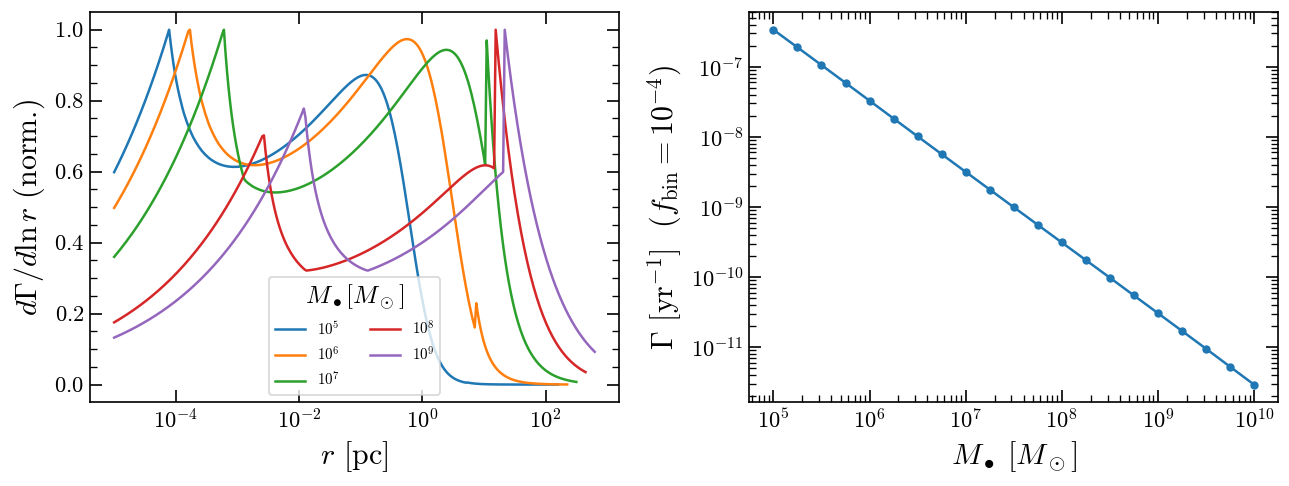

In [7]:
fig,ax=plt.subplots(1,2,figsize=(11,4.3))
lMs0=logMstar(BHMF_logM,alM0,beM0); Mnsc0=10**logMNSC(lMs0,aN0,bN0)
for lM in [5,6,7,8,9]:
    i=int(round((lM-5)/0.25)); M=10.0**lM
    r,ig=lc_integrand(LSIG[("thermal",False)][i],M,Mnsc0[i])
    ax[0].plot(r,r*ig/max((r*ig).max(),1e-300),label=rf"$10^{{{lM}}}$")
ax[0].set_xscale("log"); ax[0].set_xlabel(r"$r$ [pc]"); ax[0].set_ylabel(r"$d\Gamma/d\ln r$ (norm.)")
ax[0].legend(title=r"$M_\bullet[M_\odot]$",fontsize=9,ncol=2)
Glc=Gamma_lc_vec("thermal",False,BHMF_logM,Mnsc0)
ax[1].loglog(Mgrid,Glc,"o-",ms=4)
ax[1].set_xlabel(r"$M_\bullet\;[M_\odot]$")
ax[1].set_ylabel(r"$\Gamma$ [yr$^{-1}$]  ($f_{\rm bin}=10^{-4}$)")
fig.tight_layout(); plt.show()

## 4. Monte-Carlo rate density $\gamma\;[{\rm Gpc^{-3}\,yr^{-1}}]$

Band = systematic uncertainty (relation zero-points/slopes, $p(a,e)$ regime, $f_\mu$);
the intrinsic galaxy-to-galaxy $M_{\rm NSC}$ scatter is marginalized into the mean. 6 cases (occupation $\times$ hard/all).

In [8]:
def gamma_density(Gv,fo): return trapz(Gv*dn*fo*1e9,BHMF_logM)
OCCS=["unity","early","late"]
rng=np.random.default_rng(0); NMC=300
draws={(o,h):[] for o in OCCS for h in HARDS}
for _ in range(NMC):
    reg=REGIMES[rng.integers(3)]
    alM,beM=rng.normal(alM0,dalM),rng.normal(beM0,dbeM)
    aN,bN=rng.normal(aN0,daN),rng.normal(bN0,dbN)
    fmu_fac=10**rng.normal(0,0.10); doff=rng.normal(0,0.06)
    Mnsc_med=10**logMNSC(logMstar(BHMF_logM,alM,beM),aN,bN)
    Gh={h:Gamma_lc_vec(reg,h,BHMF_logM,Mnsc_med,fmu_fac) for h in HARDS}
    fo={o:focc_avg(o,alM,beM,doff) for o in OCCS}
    for o in OCCS:
        for h in HARDS: draws[(o,h)].append(gamma_density(Gh[h],fo[o]))
G_rate={}
print(f"gamma_2F [Gpc^-3 yr^-1]  (loss-cone; f_bin={FBIN:g}, astar={ASTAR}, abh={ABH})")
print(f"{'occupation':>10} {'binary':>6} |  median   [16-84 band]")
for o in OCCS:
    for h in HARDS:
        a=np.array(draws[(o,h)]); m,l,u=np.percentile(a,[50,16,84])
        G_rate[(o,"hard" if h else "all")]=(m,l,u)
        print(f"{o:>10} {'hard' if h else 'all':>6} |  {m:8.3g}  [{l:8.3g},{u:8.3g}]")

gamma_2F [Gpc^-3 yr^-1]  (loss-cone; f_bin=0.0001, astar=1.5, abh=2.75)
occupation binary |  median   [16-84 band]
     unity    all |     0.202  [   0.165,    0.24]
     unity   hard |     0.168  [   0.139,   0.198]
     early    all |     0.143  [   0.115,   0.173]
     early   hard |     0.119  [  0.0961,   0.144]
      late    all |     0.145  [   0.115,   0.176]
      late   hard |      0.12  [  0.0965,   0.147]


In [9]:
# ===== MC rate density for single-flare TDEs: gamma_TDE [Gpc^-3 yr^-1]  (all stars, no f_bin) =====
# Rate density uses the M_NSC-MARGINALIZED mean Gamma (Gamma_tde_vec), with systematics on the
# M_BH-M_* & M_NSC-M_* relations, occupation, and BHMF normalization (SIG_BHMF, as for 2F).
# For the INSET Gamma_TDE(M) BAND we instead draw a SINGLE-GALAXY M_NSC per mass bin (relation
# params + per-bin intrinsic 0.65-dex M_NSC scatter) and evaluate gamma_tde_one directly --
# exactly how the 2F inset bands are built -- so the green band shows the full M_NSC-relation
# scatter + uncertainty rather than the (narrow) relation-param spread about the mean.
rng=np.random.default_rng(7); NMC_T=300; SIG_BHMF=0.20
drawsT={o:[] for o in OCCS}; drawsTM=np.empty((NMC_T,len(BHMF_logM)))
for _i in range(NMC_T):
    bh=10**rng.normal(0,SIG_BHMF)                                     # BHMF normalization [dex]
    alM,beM=rng.normal(alM0,dalM),rng.normal(beM0,dbeM)
    aN,bN =rng.normal(aN0,daN), rng.normal(bN0,dbN)
    doff=rng.normal(0,0.06)
    Mnsc_med=10**logMNSC(logMstar(BHMF_logM,alM,beM),aN,bN)
    Gt=Gamma_tde_vec(BHMF_logM,Mnsc_med)                             # marginalized mean -> rate density
    for o in OCCS: drawsT[o].append(gamma_density(Gt,focc_avg(o,alM,beM,doff))*bh)
    Mnsc_gal=Mnsc_med*10**rng.normal(0,SIG_MNSC,len(BHMF_logM))      # single galaxy: + 0.65-dex intrinsic scatter
    drawsTM[_i]=np.array([gamma_tde_one(Mgrid[i],Mnsc_gal[i]) for i in range(len(BHMF_logM))])
GrTDE={}
print(f"gamma_TDE [Gpc^-3 yr^-1]  (single-flare; all stars, f=1, no f_bin; M_cut={M_TDE_CUT:.2g} Msun)")
print(f"{'occupation':>10} |  median   [16-84 band]")
for o in OCCS:
    a=np.array(drawsT[o]); m,l,u=np.percentile(a,[50,16,84]); GrTDE[o]=(m,l,u)
    print(f"{o:>10} |  {m:8.3g}  [{l:8.3g},{u:8.3g}]")
GTDE_M=np.percentile(drawsTM,[16,50,84],axis=0)   # inset Gamma_TDE(M) band: relation scatter + uncertainty


gamma_TDE [Gpc^-3 yr^-1]  (single-flare; all stars, f=1, no f_bin; M_cut=4e+07 Msun)
occupation |  median   [16-84 band]


     unity |      37.1  [    23.1,    59.9]
     early |        24  [    14.7,    38.6]
      late |      25.8  [    15.9,    42.5]


alpha_BH=2.75:  Gamma = A (M_bullet/1e8)^k   [f_bin=1e-4]
   slope   k       = -1.026 +/- 0.120
   norm    log10 A = -10.121 +/- 0.189 dex   (A = Gamma at 1e8 Msun)
   rms scatter about fit = 0.707 dex



alpha_BH=2.00:  Gamma = A (M_bullet/1e8)^k   [f_bin=1e-4]
   slope   k       = -0.838 +/- 0.094
   norm    log10 A = -10.744 +/- 0.166 dex   (A = Gamma at 1e8 Msun)
   rms scatter about fit = 0.561 dex



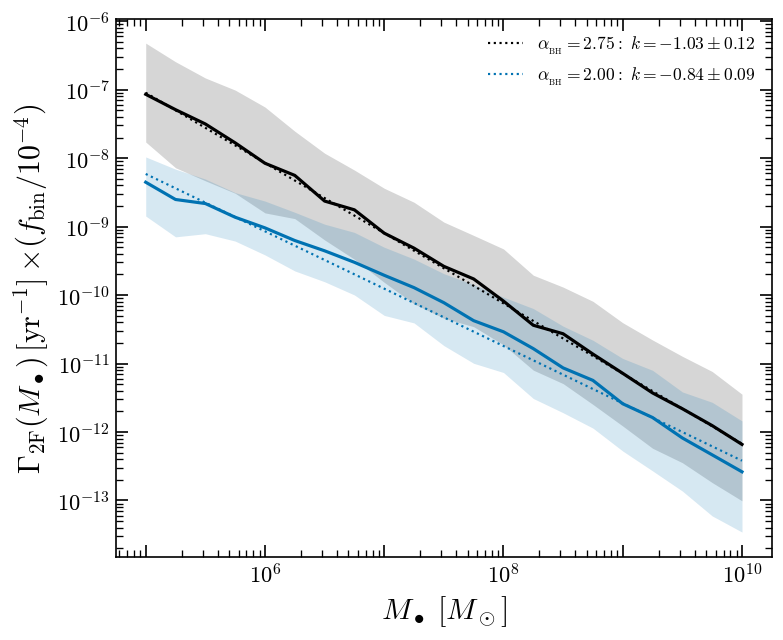

In [10]:
# ===== Power-law fits to Gamma(M_bullet) with per-parameter dex scatter from the MC =====
# Model: Gamma = A * (M_bullet / 1e8)^k  (pivot at 1e8 Msun to decorrelate slope & amplitude).
# For each alpha_BH, fit log10 Gamma = log10 A + k*(log10 M - 8) to EVERY MC realization;
# report k and log10 A as median +/- 1sigma (sigma from the realization spread), and the rms
# scatter of Gamma about the power law (in dex). Scatter sources: M_BH-M_* & Neumayer relation
# params (systematic) + 0.65-dex intrinsic M_NSC scatter + p(a,e) regime + f_mu 0.10-dex fit error.
def _even_pow(x,_):
    if x<=0: return ""
    pp=int(round(np.log10(x))); return rf"$10^{{{pp}}}$" if pp%2==0 else ""

LMref=8.0; xln=np.log10(Mgrid)-LMref                 # pivot: log10(M/1e8)
rng=np.random.default_rng(1); NMCg=400
fitres={}; bandres={}; _ABH=ABH
for abh in [2.75,2.00]:
    ABH=abh
    ks=[]; As=[]; scat=[]; draws=np.empty((NMCg,len(BHMF_logM)))
    for j in range(NMCg):
        reg=REGIMES[rng.integers(3)]
        alM,beM=rng.normal(alM0,dalM),rng.normal(beM0,dbeM)
        aN,bN =rng.normal(aN0,daN), rng.normal(bN0,dbN)
        fmu=10**rng.normal(0,0.10)
        Mnsc=10**logMNSC(logMstar(BHMF_logM,alM,beM),aN,bN)*10**rng.normal(0,SIG_MNSC,len(BHMF_logM))
        L=LSIG[(reg,False)]
        gv=np.array([gamma_lc_one(L[i],Mgrid[i],Mnsc[i],fmu) for i in range(len(BHMF_logM))])
        draws[j]=gv
        c=np.polyfit(xln,np.log10(gv),1)             # c = [k, log10 A]
        ks.append(c[0]); As.append(c[1]); scat.append(np.std(np.log10(gv)-np.polyval(c,xln)))
    ABH=_ABH
    ks=np.array(ks); As=np.array(As); scat=np.array(scat)
    fitres[abh]=((np.median(ks),np.std(ks)),(np.median(As),np.std(As)),np.median(scat))
    bandres[abh]=np.percentile(draws,[16,50,84],axis=0)
    print(f"alpha_BH={abh:.2f}:  Gamma = A (M_bullet/1e8)^k   [f_bin=1e-4]")
    print(f"   slope   k       = {np.median(ks):+.3f} +/- {np.std(ks):.3f}")
    print(f"   norm    log10 A = {np.median(As):+.3f} +/- {np.std(As):.3f} dex   (A = Gamma at 1e8 Msun)")
    print(f"   rms scatter about fit = {np.median(scat):.3f} dex\n")

COL2={2.75:"k",2.00:"#0072B2"}
fig,ax=plt.subplots(figsize=(7.0,5.4))
for abh in [2.75,2.00]:
    lo,med,hi=bandres[abh]; (km,ks_),(lAm,lAs),rms=fitres[abh]
    ax.fill_between(Mgrid,lo,hi,color=COL2[abh],alpha=0.16,lw=0)
    ax.plot(Mgrid,med,color=COL2[abh],lw=1.9)
    ax.plot(Mgrid,10**(lAm+km*(np.log10(Mgrid)-LMref)),ls=":",lw=1.3,color=COL2[abh],
            label=rf"$\alpha_{{_{{\rm BH}}}}={abh:.2f}:\ k={km:.2f}\pm{ks_:.2f}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=100)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True)
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$")
ax.set_ylabel(r"$\Gamma_{\rm 2F}(M_\bullet)\,[{\rm yr^{-1}}]\times\!\left(f_{\rm bin}/10^{-4}\right)$")
ax.set_box_aspect(0.82); ax.legend(frameon=False,loc="upper right",fontsize=10.5)
fig.subplots_adjust(left=0.17,right=0.965,top=0.95,bottom=0.12)
fig.savefig("gammaM_fit.png",bbox_inches="tight"); fig.savefig("gammaM_fit.pdf",bbox_inches="tight"); plt.show()

# Physical scaling of the per-galaxy loss-cone rate $\Gamma(M_\bullet)$

The double-flare rate per galaxy behaves, to good approximation, as a **relaxation-limited loss-cone
feeding rate**:

$$\Gamma \;\sim\; \frac{N_{\rm bin}(<r_{\rm crit})}{t_r(r_{\rm crit})},$$

i.e. the number of BH–star binaries inside the critical (empty-cone) radius, divided by the two-body
relaxation time that scatters them into the loss cone. Both factors scale with the SMBH mass, and in
**opposite** directions.

## 1. Binary reservoir grows slowly with $M_\bullet$

The binaries track the NSC mass, which follows the galaxy scaling relations:

$$N_{\rm bin}\propto M_{\rm NSC}\propto M_\star^{0.48}\propto M_\bullet^{0.30},$$

using Greene's $M_\bullet$–$M_\star$ slope ($\beta=1.61$, so $M_\star\propto M_\bullet^{1/1.61}=M_\bullet^{0.62}$) and
Neumayer's $M_{\rm NSC}\propto M_\star^{0.48}$ ($0.62\times0.48=0.30$). More massive nuclei host more binaries,
but only weakly.

## 2. Relaxation slows quickly with $M_\bullet$

With $m_\star$ and $\ln\Lambda$ fixed, $t_r\propto\sigma^3/\rho$, evaluated at the characteristic feeding
radius $r_{\rm infl}$. Propagating the model's scalings:

| quantity | scaling | origin |
|---|---|---|
| $M_{\rm NSC}$ | $\propto M_\bullet^{0.30}$ | Greene + Neumayer (above) |
| $r_{\rm eff}$ | $\propto M_{\rm NSC}^{0.5}\propto M_\bullet^{0.15}$ | Neumayer size relation |
| $r_{\rm infl}$ | $\propto M_\bullet^{0.62}$ | $M_\star(<r_{\rm infl})=M_\bullet$ with $M_\star(<r)\propto(r/r_{\rm eff})^{3-\alpha_\star}$, $\alpha_\star=\tfrac32\Rightarrow$ exponent $1/(3-\alpha_\star)=0.67$ |
| $\sigma$ | $\propto(M_\bullet/r_{\rm infl})^{1/2}\propto M_\bullet^{0.19}$ | Keplerian cusp, $\sigma^2\sim GM_\bullet/r$ |
| $\rho(r_{\rm infl})$ | $\propto M_{\rm NSC}\,r_{\rm eff}^{\alpha_\star-3}\,r_{\rm infl}^{-\alpha_\star}\propto M_\bullet^{-0.85}$ | power-law field density |

Hence

$$t_r\propto\frac{\sigma^3}{\rho}\propto M_\bullet^{\,3(0.19)-(-0.85)}=M_\bullet^{0.58+0.85}\approx M_\bullet^{1.43}.$$

Physically: deeper potentials raise $\sigma$ and lower the central density, both lengthening the relaxation
time that refills the loss cone. (All exponents above are reproduced by the full model to $\lesssim0.01$.)

## Net result

$$\boxed{\;\Gamma\sim\frac{N_{\rm bin}}{t_r}\propto M_\bullet^{\,0.30-1.43}\approx M_\bullet^{-1.1}\;}$$

in good agreement with the numerical fit, $\Gamma\propto M_\bullet^{-1.03}$ (for the fiducial
$\alpha_{\rm BH}=11/4$). This is the standard **loss-cone trend** — lower-mass nuclei feed faster — here
*steepened* by the sublinear $M_{\rm NSC}$–$M_\bullet$ relation.

## Dependence on the cusp slope

The exact exponent depends on the heavy-cusp slope $\alpha_{\rm BH}$ (Alexander & Hopman 2009), because that
sets where the binaries sit relative to $r_{\rm crit}$:

| $\alpha_{\rm BH}$ | fitted slope |
|---|---|
| $11/4$ (strong seg.) | $\Gamma\propto M_\bullet^{-1.03}$ |
| $2$ (shallow seg.) | $\Gamma\propto M_\bullet^{-0.84}$ |

A steeper cusp concentrates binaries at small $r$ where $t_r$ is shortest, so the rate is more sensitive to the
inner relaxation and declines slightly faster with $M_\bullet$.

> Note: $M$–$\sigma$ does **not** enter this scaling — $\sigma(r)$ is obtained from the enclosed mass via the
> Jeans equation, so the galaxy dependence comes entirely through the $M_\bullet$–$M_\star$–$M_{\rm NSC}$ chain.

In [11]:
# ===== gamma_2F built FROM the Gamma(M) power-law fits (two alpha_BH) =====
# Requires 'fitres' from the previous cell: fitres[abh] = ((k, sk), (log10A, slA), rms).
#   gamma_2F = \int A (M/1e8)^k * boost * (dn/dlogM) * f_occ  dlogM            [Gpc^-3 yr^-1]
#   boost = 10^(rms^2 ln10 / 2): converts the fitted MEDIAN Gamma(M) to the population MEAN
#           that the rate density requires (validated to ~5% vs the exact GH-marginalized gamma).
# Scatter propagated (MC): fit slope k and amplitude log10A (their 1-sigma), BHMF normalization,
#   and occupation (M_BH-M_* params + offset).  f_bin = 1e-4.
LN10 = np.log(10.0); xln8 = BHMF_logM - 8.0
SIG_BHMF = 0.20                 # Greene+2020 BHMF normalization uncertainty [dex] (representative; adjust)
rng = np.random.default_rng(5); NMC2 = 3000
print(f"gamma_2F from the Gamma(M) power-law fits   [Gpc^-3 yr^-1, f_bin=1e-4, SIG_BHMF={SIG_BHMF} dex]")
print(f"{'alpha_BH':>8} {'occ':>7} |  median   [16-84 band]      (fit: k, log10A at 1e8)")
for abh in [2.75, 2.00]:
    (km, sk), (lAm, slA), rms = fitres[abh]
    boost = 10**(rms**2 * LN10 / 2)
    draws = {o: [] for o in OCCS}
    for _ in range(NMC2):
        k   = rng.normal(km, sk)
        lA  = rng.normal(lAm, slA)
        bh  = 10**rng.normal(0, SIG_BHMF)                 # BHMF normalization scatter
        alM, beM = rng.normal(alM0, dalM), rng.normal(beM0, dbeM)
        doff = rng.normal(0, 0.06)
        Gfit = 10**(lA + k*xln8) * boost                  # mean Gamma(M) [1/yr]
        for o in OCCS:
            draws[o].append(trapz(Gfit * dn * bh * focc_avg(o, alM, beM, doff) * 1e9, BHMF_logM))
    for o in OCCS:
        a = np.array(draws[o]); m, lo, hi = np.percentile(a, [50, 16, 84])
        tag = f"k={km:+.2f}+/-{sk:.2f}, logA={lAm:+.2f}+/-{slA:.2f}" if o == "unity" else ""
        print(f"{abh:8.2f} {o:>7} |  {m:7.3g}  [{lo:7.3g}, {hi:7.3g}]   {tag}")

gamma_2F from the Gamma(M) power-law fits   [Gpc^-3 yr^-1, f_bin=1e-4, SIG_BHMF=0.2 dex]
alpha_BH     occ |  median   [16-84 band]      (fit: k, log10A at 1e8)
    2.75   unity |     0.19  [ 0.0743,   0.522]   k=-1.03+/-0.12, logA=-10.12+/-0.19
    2.75   early |    0.134  [ 0.0513,   0.372]   
    2.75    late |    0.135  [ 0.0518,   0.372]   
    2.00   unity |  0.00935  [0.00424,  0.0207]   k=-0.84+/-0.09, logA=-10.74+/-0.17
    2.00   early |  0.00644  [ 0.0029,  0.0146]   
    2.00    late |  0.00657  [0.00298,  0.0148]   


### Sensitivity to the heavy-cusp slope $\alpha_{\rm BH}$

$\alpha_{\rm BH}=11/4$ is the maximal strong-segregation slope; for finite $\Delta$ it is shallower (2–2.75).
Median-relation $\gamma$ (all pairs) vs $\alpha_{\rm BH}$ to bracket the range.

In [12]:
lMs0=logMstar(BHMF_logM,alM0,beM0); Mnsc0=10**logMNSC(lMs0,aN0,bN0)
_ABH=ABH
print(f"{'alpha_BH':>8} | " + "  ".join(f"{o:>7}" for o in OCCS) + "   [Gpc^-3 yr^-1, all pairs]")
for abh in [2.0,2.25,2.5,2.75]:
    ABH=abh
    Gv=Gamma_lc_vec("thermal",False,BHMF_logM,Mnsc0)
    row=[gamma_density(Gv,focc_avg(o,alM0,beM0,0.0)) for o in OCCS]
    print(f"{abh:8.2f} | " + "  ".join(f"{v:7.3g}" for v in row))
ABH=_ABH

alpha_BH |   unity    early     late   [Gpc^-3 yr^-1, all pairs]
    2.00 | 0.00512  0.00352  0.00364
    2.25 |  0.0121  0.00845  0.00864
    2.50 |  0.0387   0.0273   0.0276
    2.75 |   0.197    0.139     0.14


## 5. Observer-frame cumulative rate $R_{\rm 2F}(<z)$

$R_{\rm 2F}(<z)=\int_0^z \frac{\gamma}{1+z'}\frac{dV_c}{dz'}dz'$ (Planck18, $\gamma$ constant in comoving volume);
redshift on the bottom axis, $D_L$ on top. Scales as $f_{\rm bin}/10^{-4}$.

The **shaded band** on the fiducial ($\alpha_{\rm BH}=11/4$) curves is the *systematic* uncertainty — scaling-relation
zero-points/slopes, $p(a,e)$ regime, and the $f_\mu$ 0.10-dex fit scatter — only $\approx\pm0.08$ dex ($\pm18\%$),
dominated by the galaxy-relation systematics. The large intrinsic galaxy-to-galaxy scatter (0.50 dex in $M_\star$,
0.6 dex in $M_{\rm NSC}$) is marginalized into the mean, not drawn. The thin dashed lines are the shallow
strong-segregation slope $\alpha_{\rm BH}=2$ — the dominant ($\sim$1.6 dex) uncertainty, far larger than the band.

**Single-flare TDEs (green):** the ordinary star$-$SMBH TDE rate from the same loss-cone model (all stars, $f=1$, no $f_{\rm bin}$; cut at $r_t=4R_g$) is overlaid for comparison (unity occupation + systematic band). It is absolute, so the 2F/TDE ratio scales $\propto f_{\rm bin}$. The inset adds $\Gamma_{\rm TDE}(M_\bullet)$ (green), truncated at $M_{\rm cut}\approx4\times10^7\,M_\odot$.


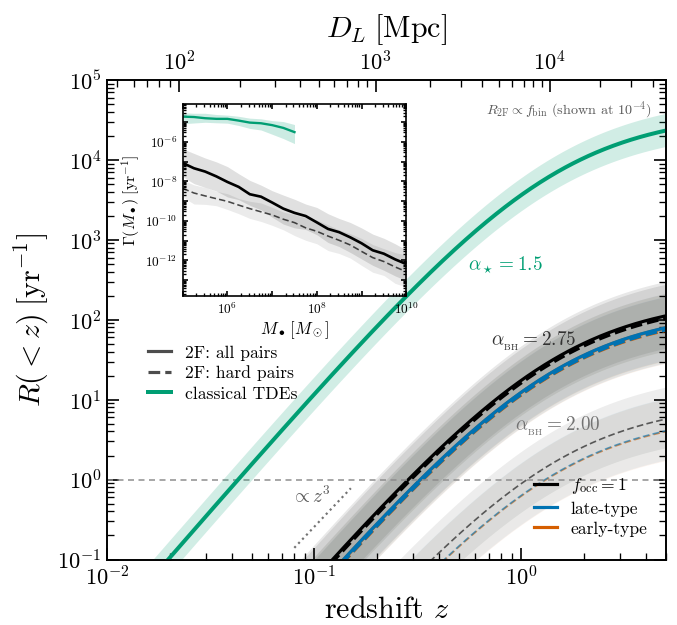

In [13]:
# ===== R_2F(<z) from the Gamma(M) power-law fits (alpha_BH=2.75 & 2.00), with Gamma_2F(M) inset =====
# Self-contained: fits Gamma(M) for the (alpha_BH,hard/all) cases, builds gamma_2F (median->mean
# boost + fit-parameter scatter + BHMF normalization + occupation), integrates to R_2F(<z), and
# adds an upper-left inset of Gamma_2F(M) with the two power-law fits.  f_bin = 1e-4.
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u
xln8=BHMF_logM-8.0; LN10=np.log(10.0); SIG_BHMF=0.20

# --- fit Gamma(M) per (alpha_BH, hard); also keep Gamma(M) band for the inset (all pairs) ---
cases=[(2.75,False),(2.75,True),(2.00,False)]; Gpar={}; GM={}; rng=np.random.default_rng(1); NF=300; _ABH=ABH
for abh,hard in cases:
    ABH=abh; ks=[]; As=[]; sc=[]; dr=np.empty((NF,len(BHMF_logM)))
    for j in range(NF):
        reg=REGIMES[rng.integers(3)]
        alM,beM=rng.normal(alM0,dalM),rng.normal(beM0,dbeM); aN,bN=rng.normal(aN0,daN),rng.normal(bN0,dbN)
        fmu=10**rng.normal(0,0.10)
        Mnsc=10**logMNSC(logMstar(BHMF_logM,alM,beM),aN,bN)*10**rng.normal(0,SIG_MNSC,len(BHMF_logM))
        L=LSIG[(reg,hard)]; gv=[gamma_lc_one(L[i],Mgrid[i],Mnsc[i],fmu) for i in range(len(BHMF_logM))]
        dr[j]=gv; lg=np.log10(gv); c=np.polyfit(xln8,lg,1); ks.append(c[0]); As.append(c[1]); sc.append(np.std(lg-np.polyval(c,xln8)))
    Gpar[(abh,hard)]=((np.median(ks),np.std(ks)),(np.median(As),np.std(As)),np.median(sc))
    if not hard: GM[abh]=np.percentile(dr,[16,50,84],axis=0)
ABH=_ABH

# --- fit-based gamma_2F (median,16,84) per (alpha_BH, hard, occ) ---
rng=np.random.default_rng(5); NMC2=2000; acc={(a,h,o):[] for (a,h) in cases for o in OCCS}
for _ in range(NMC2):
    bh=10**rng.normal(0,SIG_BHMF); alM,beM=rng.normal(alM0,dalM),rng.normal(beM0,dbeM); doff=rng.normal(0,0.06)
    foc={o:focc_avg(o,alM,beM,doff) for o in OCCS}
    for (a,h) in cases:
        (km,sk),(lAm,slA),rms=Gpar[(a,h)]; boost=10**(rms**2*LN10/2); k=rng.normal(km,sk); lA=rng.normal(lAm,slA); Gfit=10**(lA+k*xln8)*boost
        for o in OCCS: acc[(a,h,o)].append(trapz(Gfit*dn*bh*foc[o]*1e9,BHMF_logM))
Gr={key:np.percentile(v,[50,16,84]) for key,v in acc.items()}

# --- observer-frame cumulative rate ---
COL={"unity":"k","late":"#0072B2","early":"#D55E00"}; CAB={2.75:"k",2.00:"#0072B2"}
XMIN,ZMAX,YMIN=0.01,5.0,1e-1
z=np.logspace(-3,np.log10(ZMAX),700)
dVdz=cosmo.differential_comoving_volume(z).to(u.Mpc**3/u.sr).value*4*np.pi
DL=cosmo.luminosity_distance(z).to(u.Mpc).value
def Rate(gm):
    integ=(gm*1e-9)/(1+z)*dVdz
    return np.concatenate([[0.0],np.cumsum(0.5*(integ[1:]+integ[:-1])*np.diff(z))])
fig,ax=plt.subplots(figsize=(7.0,5.4)); allhi=0.0
for o in OCCS:                                   # fiducial alpha_BH = 2.75 : all + hard
    for h,ls in [(False,"-"),(True,"--")]:
        med,lo,hi=Gr[(2.75,h,o)]
        ax.fill_between(z,Rate(lo),Rate(hi),color=COL[o],alpha=0.09,lw=0)
        ax.plot(z,Rate(med),color=COL[o],ls=ls,lw=1.9); allhi=max(allhi,Rate(hi).max())
R200u=None
for o in OCCS:                                   # shallow alpha_BH = 2.00 : all pairs (thin)
    med,lo,hi=Gr[(2.00,False,o)]
    ax.fill_between(z,Rate(lo),Rate(hi),color=COL[o],alpha=0.07,lw=0)
    ax.plot(z,Rate(med),color=COL[o],lw=1.0,alpha=0.6,ls=(0,(4,2)))
    if o=="unity": R200u=Rate(med)
Rtop=Rate(Gr[(2.75,False,"unity")][0])
# --- single-flare TDE (all stars onto the SMBH, no f_bin): unity occ + systematic band ---
mT,loT,hiT=GrTDE["unity"]; RmT=Rate(mT)   # unity median + its symmetric 16-84 systematic band
ax.fill_between(z,Rate(loT),Rate(hiT),color="#009E73",alpha=0.18,lw=0,zorder=4)
ax.plot(z,RmT,color="#009E73",lw=2.4,zorder=6)
allhi=max(allhi,Rate(hiT).max())
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(XMIN,ZMAX); ax.set_ylim(YMIN,10**np.ceil(np.log10(allhi)))
# slope labels (above their lines, not touching)
ztop=1.15; ax.text(ztop,np.interp(ztop,z,Rtop)*1.75,r"$\alpha_{_{\rm BH}}=2.75$",color="0.2",fontsize=11.5,ha="center",va="bottom")
zlab=1.5; ax.text(zlab,np.interp(zlab,z,R200u)*1.9,r"$\alpha_{_{\rm BH}}=2.00$",color="0.45",fontsize=11.5,ha="center",va="bottom")
zlt=0.5; ax.text(zlt*1.1,np.interp(zlt,z,RmT)*0.8,r"$\alpha_\star=1.5$",color="#009E73",fontsize=11.5,ha="left",va="top",zorder=7)
# short propto z^3 guide, left of the 2.75 band, kept below the R=1 line
m=Rtop>0; yv=np.array([0.14,0.78]); zc=10**np.interp(np.log10(yv),np.log10(Rtop[m]),np.log10(z[m])); zgd=0.58*zc
ax.plot(zgd,yv,ls=":",lw=1.3,color="0.45",zorder=5)
ax.annotate(r"$\propto z^{3}$",(zgd[1]*0.80,yv[1]*0.80),color="0.35",fontsize=11.5,ha="right",va="center")
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"redshift $z$")
ax.set_ylabel(r"$R(<z)\;[{\rm yr^{-1}}]$"); ax.set_box_aspect(0.82)
ax.text(0.975,0.96,r"$R_{\rm 2F}\propto f_{\rm bin}$ (shown at $10^{-4}$)",transform=ax.transAxes,fontsize=8.5,color="0.35",va="top",ha="right")
ax.axhline(1.0,color="0.55",lw=0.9,ls=(0,(4,3)))
# top axis D_L
DL2z=lambda dl:np.interp(dl,DL,z); secax=ax.twiny(); secax.set_xscale("log"); secax.set_xlim(ax.get_xlim())
DLmin,DLmax=np.interp(XMIN,z,DL),DL.max(); maj=[v for v in [1,10,100,1e3,1e4] if DLmin<=v<=DLmax]
minr=[mm*10.0**kk for kk in range(0,5) for mm in range(2,10)]; minr=[v for v in minr if DLmin<=v<=DLmax]
secax.xaxis.set_major_locator(FixedLocator([DL2z(v) for v in maj])); secax.xaxis.set_major_formatter(FixedFormatter([rf"$10^{{{int(round(np.log10(v)))}}}$" for v in maj]))
secax.xaxis.set_minor_locator(FixedLocator([DL2z(v) for v in minr])); secax.xaxis.set_minor_formatter(NullFormatter())
secax.tick_params(direction="in",which="both",top=True); secax.set_xlabel(r"$D_L\;[{\rm Mpc}]$",fontsize=18,labelpad=8)
# legends: linestyle key upper-right, colour key lower-right
col_h=[Line2D([],[],color=COL["unity"],lw=1.9),Line2D([],[],color=COL["late"],lw=1.9),Line2D([],[],color=COL["early"],lw=1.9)]
ls_h=[Line2D([],[],color="0.3",lw=1.9,ls="-"),Line2D([],[],color="0.3",lw=1.9,ls="--"),Line2D([],[],color="#009E73",lw=2.4,ls="-")]
leg1=ax.legend(ls_h,["2F: all pairs","2F: hard pairs","classical TDEs"],frameon=False,loc="upper left",bbox_to_anchor=(0.045,0.48),handlelength=1.3,labelspacing=0.28,fontsize=10.5); ax.add_artist(leg1)
ax.legend(col_h,[r"$f_{\rm occ}=1$","late-type","early-type"],frameon=False,loc="lower right",bbox_to_anchor=(0.995,0.015),handlelength=1.3,labelspacing=0.28,fontsize=10.5)
# inset: Gamma_2F(M) in the upper-left
axi=ax.inset_axes([0.135,0.55,0.40,0.40])
axi.set_zorder(12); axi.patch.set_facecolor("white"); axi.patch.set_alpha(1.0)
for abh,_lw,_ls,_al,_ba in [(2.75,1.6,"-",1.0,0.12),(2.00,0.95,(0,(4,2)),0.70,0.08)]:
    lo,med,hi=GM[abh]
    axi.fill_between(Mgrid,lo,hi,color=COL["unity"],alpha=_ba,lw=0)
    axi.plot(Mgrid,med,color=COL["unity"],lw=_lw,ls=_ls,alpha=_al)
_loT,_mdT,_hiT=GTDE_M; _mT=_mdT>0
axi.fill_between(Mgrid[_mT],_loT[_mT],_hiT[_mT],color="#009E73",alpha=0.20,lw=0)
axi.plot(Mgrid[_mT],_mdT[_mT],color="#009E73",lw=1.4)
axi.set_xscale("log"); axi.set_yscale("log"); axi.set_xlim(1e5,1e10)
axi.xaxis.set_major_locator(LogLocator(base=10,numticks=20)); axi.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:(rf"$10^{{{int(round(np.log10(x)))}}}$" if x>0 and int(round(np.log10(x)))%2==0 else "")))
axi.yaxis.set_major_locator(LogLocator(base=10,numticks=20)); axi.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,_:(rf"$10^{{{int(round(np.log10(y)))}}}$" if y>0 and int(round(np.log10(y)))%2==0 else "")))
axi.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); axi.xaxis.set_minor_formatter(NullFormatter())
axi.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); axi.yaxis.set_minor_formatter(NullFormatter())
axi.tick_params(which="both",direction="in",labelsize=8,length=3); axi.tick_params(which="minor",length=1.7)
axi.set_xlabel(r"$M_\bullet\,[M_\odot]$",fontsize=10,labelpad=1.5); axi.set_ylabel(r"$\Gamma(M_\bullet)\;[{\rm yr^{-1}}]$",fontsize=9.5,labelpad=1.5)
fig.subplots_adjust(left=0.30,right=0.965,top=0.86,bottom=0.12)
fig.savefig("horizon_inset.png",bbox_inches="tight"); fig.savefig("horizon_inset.pdf",bbox_inches="tight"); plt.show()


## Summary — NSC single-star$-$single-BH $\mu$TDE channel & the Alexander–Hopman cusp slopes

**On the NSC collisional $\mu$TDE channel (explored, then removed).** We considered a third channel: field $10\,M_\odot$ BHs tidally disrupting passing $1\,M_\odot$ stars via two-body encounters in the NSC, $\Gamma=\int n_\star(r)\,n_{\rm BH}(r)\,\Sigma(r)\,v_{\rm rel}(r)\,4\pi r^2\,dr$, with gravitational-focusing cross-section to $r_t=R_\odot(m_{\rm BH}/m_\star)^{1/3}$, $v_{\rm rel}=\sqrt2\,\sigma(r)$ from Jeans, and the BH population normalized to $N_{\rm BH}=f_{\rm BH}N_\star$ with $f_{\rm BH}\approx1.8\times10^{-3}$ (Kroupa IMF; all $20\!-\!150\,M_\odot$ stars $\to$ one retained $10\,M_\odot$ BH). The integrand scales as $r^{\,1-\alpha_{\rm BH}}$ in the focusing regime, so the rate is set by the inner cutoff: marginally (logarithmic) for $\alpha_{\rm BH}=2.0$, genuinely power-law divergent for $\alpha_{\rm BH}=2.75$. We replaced the overly conservative influence-radius cutoff with the discreteness floor $r_{\rm min}=\max(r_{1\star},r_{1,\rm BH})$ (radius enclosing one star / one BH — stars bind for the steep $2.75$ cusp, BHs for $2.0$), floored by the SMBH tidal-shear radius $r_q=(3M_\bullet/m_\star)^{1/3}R_\odot\simeq1.44\,r_{t,\rm SMBH}$. This gave a robust, sensible rate for $\alpha_{\rm BH}=2.0$ ($\gamma\approx0.25\,{\rm Gpc^{-3}yr^{-1}}$, comparable to the 2F channel), but for $\alpha_{\rm BH}=2.75$ it produced $\gamma\approx7000\,{\rm Gpc^{-3}yr^{-1}}$ — $\sim190\times$ the classical TDE rate — because the steep segregated cusp, carrying its full normalization, must be extrapolated $\sim4$ decades inward (e.g. $\sim660$ BHs within $72$ AU of a $10^6\,M_\odot$ SMBH), far below where the AH09 solution is derived. Since the result is entirely controlled by that untrustworthy extrapolation, we removed the channel from the figure rather than quote a cutoff-dominated number.

**On the cusp power-law slopes (Alexander & Hopman 2009).** Around an SMBH a relaxed system forms a cusp $n(r)\propto r^{-\alpha}$; the single-mass Bahcall–Wolf (1976) solution gives $\alpha=7/4$. For two mass groups, AH09 define a segregation parameter $\Delta=4N_H m_H^2/[N_L m_L^2(3+m_H/m_L)]$: $\Delta\gg1$ is weak segregation (both $\approx7/4$), while $\Delta\ll1$ is **strong** segregation, where the light stars relax to $\alpha_\star\to3/2$ and the rare heavy BHs steepen to $2\lesssim\alpha_{\rm BH}<11/4$ (the bound $11/4=7/4+1$ following from $\max(\alpha_H-\alpha_L)\simeq1$). For our NSC ($m_H/m_L=10$, $N_H/N_L\approx f_{\rm BH}\approx1.8\times10^{-3}$), $\Delta\approx0.057\ll1$ — firmly strong segregation. We therefore fix $\alpha_\star=3/2$ and bracket the BH cusp with the two ends of the AH09 strong-regime range, $\alpha_{\rm BH}=2.0$ (conservative) and $\alpha_{\rm BH}=2.75=11/4$ (strong-segregation maximum); AH09 give no closed-form $\alpha_{\rm BH}(m_H/m_L)$ for the strong branch (the mass ratio enters only through $\Delta$), so bracketing is the honest choice. Later Fokker–Planck work (Linial & Sari 2022) finds realized slopes nearer $\sim2.1\!-\!2.3$ for a 10:1 mixture, so $2.75$ is best read as the steep extreme rather than the expected value.
